In [73]:
!pip install -q optuna pytorch-tabnet xgboost lightgbm

In [74]:
import json
import random
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import torch

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
from pytorch_tabnet.metrics import Metric

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_PATH = "/kaggle/input/datasets/mohankrishnathalla/credit-card-fraud-detection-with-drift-2026/credit_card_fraud_drift_2026.csv"

TARGET_COL = "is_fraud"
TIME_COL = "transaction_datetime"
PHASE_COL = "drift_phase"
ELIGIBILITY_COL = "transaction_time_eligible"

N_OPTUNA_TRIALS = 10
TABNET_MAX_EPOCHS = 50
TABNET_PATIENCE = 3
PREDICTION_THRESHOLD = 0.50

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [75]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

df_raw[TIME_COL] = pd.to_datetime(df_raw[TIME_COL], errors="coerce")
df_raw[PHASE_COL] = pd.to_numeric(df_raw[PHASE_COL], errors="coerce")
df_raw[ELIGIBILITY_COL] = pd.to_numeric(df_raw[ELIGIBILITY_COL], errors="coerce")
df_raw[TARGET_COL] = pd.to_numeric(df_raw[TARGET_COL], errors="coerce")

required_columns = [
    TARGET_COL,
    TIME_COL,
    PHASE_COL,
    ELIGIBILITY_COL
]

candidate_features = [
    "transaction_amount",
    "merchant_category",
    "merchant_country",
    "transaction_hour",
    "transaction_day_of_week",
    "card_present",
    "customer_age",
    "customer_country",
    "account_age_days",
    "credit_limit",
    "credit_score",
    "num_cards_held",
    "distance_from_home_km",
    "international_transaction",
    "high_risk_country",
    "amount_vs_avg_ratio",
    "used_chip",
    "used_pin",
    "transaction_channel",
    "device_type",
    "browser",
    "is_weekend",
    "email_domain"
]

required_columns = required_columns + candidate_features
assert set(required_columns).issubset(df_raw.columns)

print("Original dataset shape:", df_raw.shape)
print("Original date range:", df_raw[TIME_COL].min(), "to", df_raw[TIME_COL].max())
print("Original phase distribution:")
display(df_raw[PHASE_COL].value_counts(dropna=False).sort_index().rename("rows").to_frame())
display(df_raw.head())


Original dataset shape: (120000, 73)
Original date range: 2026-01-01 00:00:00 to 2026-06-30 23:58:00
Original phase distribution:


,rows
drift_phase,
1,39133
2,20445
3,40586
4,19836


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,TX4042000000000,CU00022008,CA000000001,ME000381,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,TX4042000000001,CU00000598,CA000000002,ME000764,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,TX4042000000002,CU00018179,CA000000003,ME001251,2026-01-01 00:03:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,TX4042000000003,CU00023636,CA000000004,ME002627,2026-01-01 00:04:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,TX4042000000004,CU00028521,CA000000005,ME004940,2026-01-01 00:05:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period


In [76]:
df = df_raw.loc[
    df_raw[ELIGIBILITY_COL].eq(1)
].copy()

df = df.dropna(
    subset=[TIME_COL, PHASE_COL, TARGET_COL]
).copy()

df[TARGET_COL] = df[TARGET_COL].astype(int)
df[PHASE_COL] = df[PHASE_COL].astype(int)

df = df.sort_values(TIME_COL).reset_index(drop=True)

print("Eligible dataset shape:", df.shape)
print("Eligible transaction count:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df["transaction_id"].duplicated().sum())
print("Rows by drift phase:")
display(df[PHASE_COL].value_counts().sort_index().rename("rows").to_frame())
display(df[required_columns].dtypes.astype(str).rename("dtype").to_frame())
display(df[candidate_features].head())


Eligible dataset shape: (118107, 73)
Eligible transaction count: 118107
Duplicate rows: 0
Duplicate transaction IDs: 0
Rows by drift phase:


,rows
drift_phase,
1,38476
2,20141
3,39945
4,19545


,dtype
is_fraud,int64
transaction_datetime,datetime64[ns]
drift_phase,int64
transaction_time_eligible,int64
transaction_amount,float64
merchant_category,object
merchant_country,object
transaction_hour,int64
transaction_day_of_week,object
card_present,int64


,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_country,account_age_days,credit_limit,...,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,email_domain
0,16.34,subscription,SG,0,Thursday,0,36,GB,139,21245.40,...,0,0,0.3268,0,0,mobile_app,unknown_device,Chrome,0,outlook.com
1,27.88,grocery,IE,0,Thursday,0,40,IE,937,3382.44,...,1,0,0.5576,0,0,mobile_app,mobile,in_app,0,icloud.com
2,24.71,grocery,IN,0,Thursday,1,56,US,313,2405.17,...,0,0,0.4942,0,0,POS,physical_terminal,none,0,business.com
3,62.07,electronics,US,0,Thursday,1,27,US,266,3215.98,...,1,0,1.2414,1,1,POS,physical_terminal,none,0,gmail.com
4,46.23,health,US,0,Thursday,1,21,US,796,3937.88,...,0,1,0.9246,1,1,POS,physical_terminal,none,0,yahoo.com


,count,percentage
is_fraud,,
Non-Fraud,53956,92.048382
Fraud,4661,7.951618


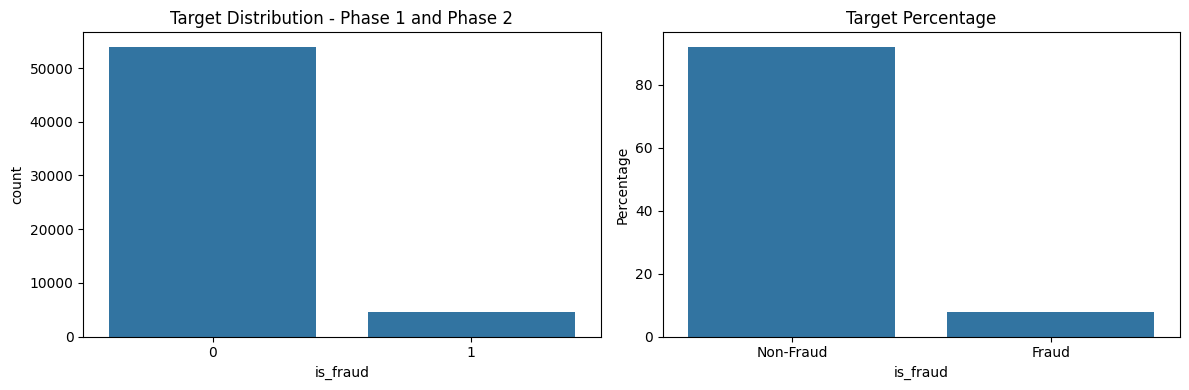

In [77]:
eda_df = df.loc[df[PHASE_COL].isin([1, 2])].copy()

target_distribution = (
    eda_df[TARGET_COL]
    .value_counts()
    .sort_index()
    .rename(index={0: "Non-Fraud", 1: "Fraud"})
)

target_percentage = (
    eda_df[TARGET_COL]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .rename(index={0: "Non-Fraud", 1: "Fraud"})
)

display(
    target_distribution.rename("count").to_frame()
    .join(target_percentage.rename("percentage"))
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=eda_df, x=TARGET_COL, ax=axes[0])
axes[0].set_title("Target Distribution - Phase 1 and Phase 2")
sns.barplot(
    x=target_percentage.index,
    y=target_percentage.values,
    ax=axes[1]
)
axes[1].set_title("Target Percentage")
axes[1].set_ylabel("Percentage")
plt.tight_layout()
plt.show()


,missing_percentage
transaction_amount,0.0
merchant_category,0.0
merchant_country,0.0
transaction_hour,0.0
transaction_day_of_week,0.0
card_present,0.0
customer_age,0.0
customer_country,0.0
account_age_days,0.0
credit_limit,0.0


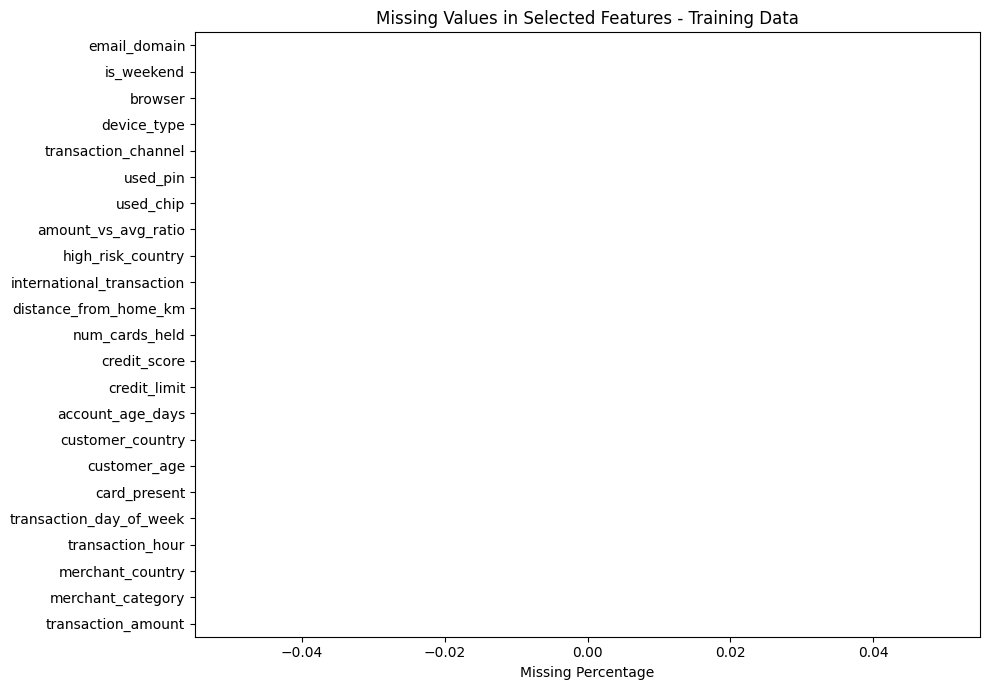

In [78]:
train_eda_df = df.loc[df[PHASE_COL].eq(1)].copy()

missing_summary = (
    train_eda_df[candidate_features]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percentage")
    .to_frame()
)

display(missing_summary)

missing_summary.sort_values("missing_percentage").plot(
    kind="barh",
    figsize=(10, 7),
    legend=False
)
plt.title("Missing Values in Selected Features - Training Data")
plt.xlabel("Missing Percentage")
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
transaction_amount,38476.0,46.722285,37.998625,1.9900,22.6500,36.21,58.35250,853.0600
transaction_hour,38476.0,11.457870,6.918598,0.0000,5.0000,11.00,17.00000,23.0000
card_present,38476.0,0.487759,0.499857,0.0000,0.0000,0.00,1.00000,1.0000
customer_age,38476.0,41.912491,13.411710,18.0000,32.0000,42.00,51.00000,90.0000
account_age_days,38476.0,772.598815,894.174149,15.0000,249.0000,469.00,928.00000,19953.0000
credit_limit,38476.0,6731.852975,5426.225918,500.0000,3224.1625,5244.16,8431.06000,73621.8600
credit_score,38476.0,688.752651,64.089943,300.0000,646.0000,689.00,732.00000,850.0000
num_cards_held,38476.0,2.828516,1.342721,1.0000,2.0000,3.00,4.00000,8.0000
distance_from_home_km,38476.0,18.388492,25.226251,0.1100,5.3700,10.69,21.67000,816.4100
international_transaction,38476.0,0.114903,0.318909,0.0000,0.0000,0.00,0.00000,1.0000


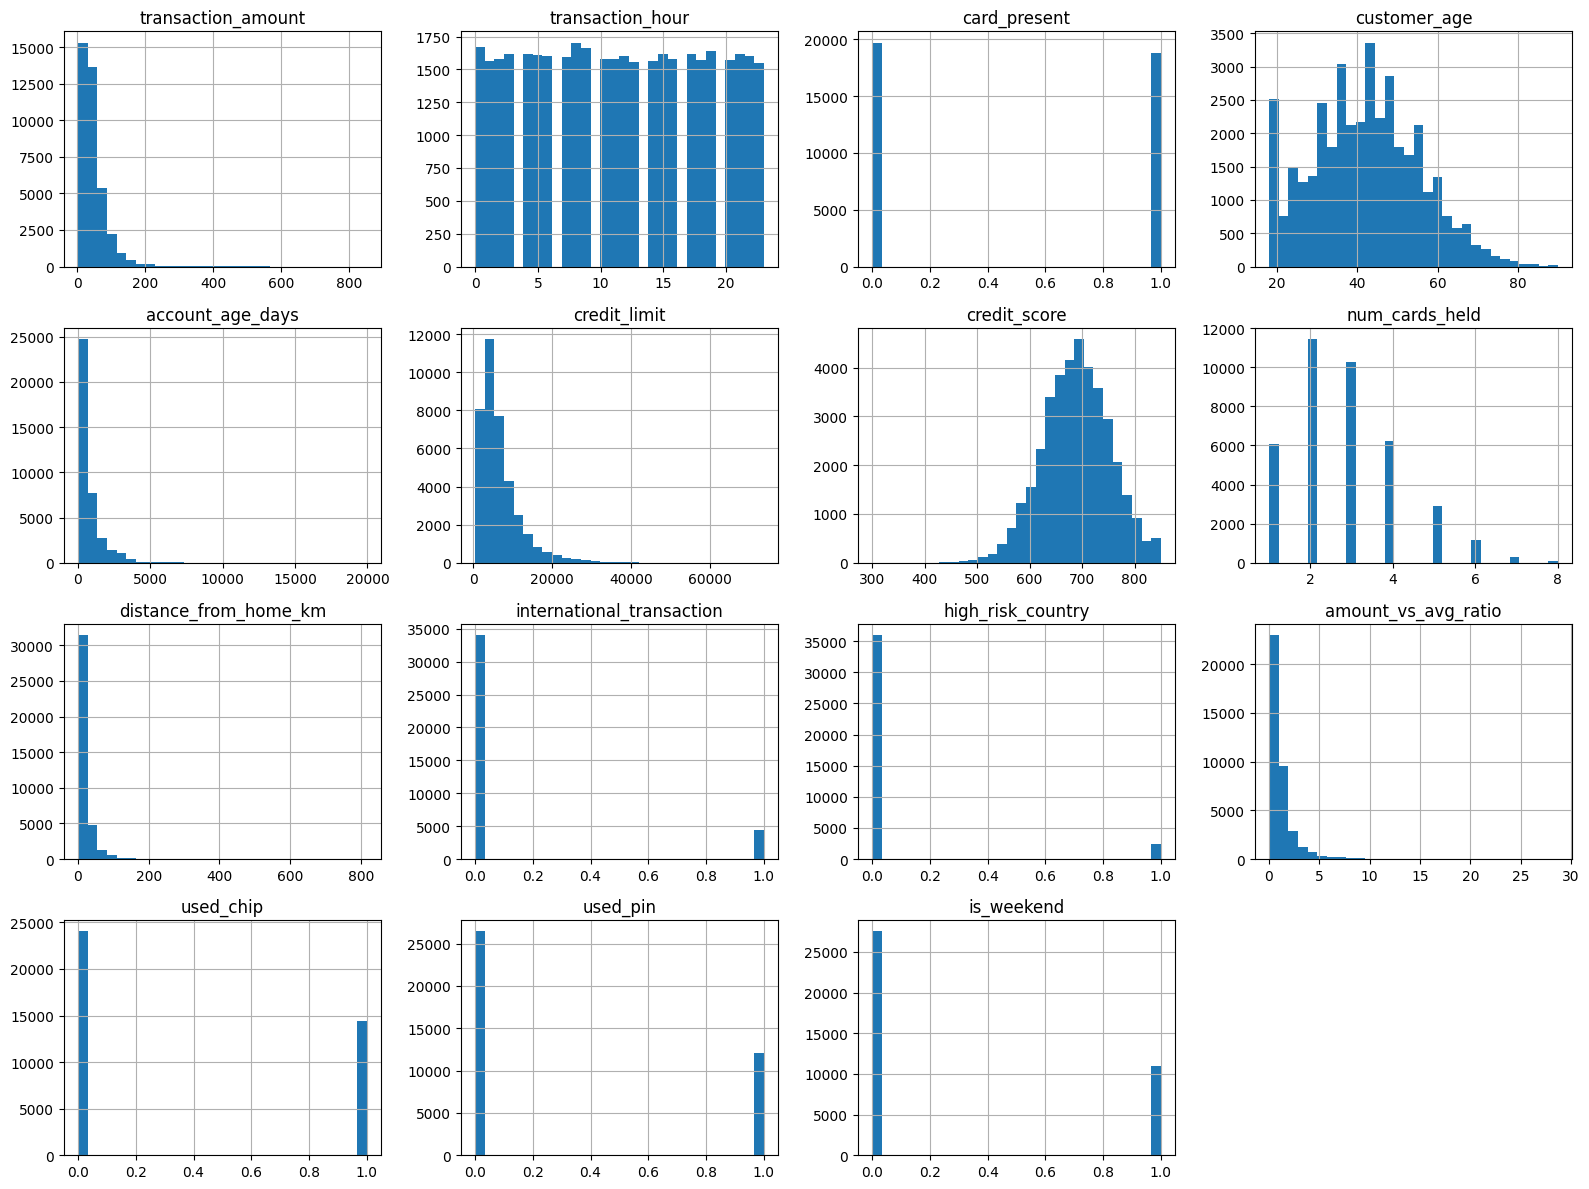

,feature,unique_categories,missing_percentage
0,merchant_category,10,0.0
1,merchant_country,12,0.0
2,transaction_day_of_week,7,0.0
3,customer_country,12,0.0
4,transaction_channel,5,0.0
5,device_type,5,0.0
6,browser,6,0.0
7,email_domain,7,0.0


In [79]:
numeric_eda_features = train_eda_df[candidate_features].select_dtypes(
    include=np.number
).columns.tolist()

categorical_eda_features = train_eda_df[candidate_features].select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

display(train_eda_df[numeric_eda_features].describe().T)

train_eda_df[numeric_eda_features].hist(
    figsize=(16, 12),
    bins=30
)
plt.tight_layout()
plt.show()

categorical_summary = pd.DataFrame({
    "feature": categorical_eda_features,
    "unique_categories": [
        train_eda_df[column].nunique(dropna=True)
        for column in categorical_eda_features
    ],
    "missing_percentage": [
        train_eda_df[column].isna().mean() * 100
        for column in categorical_eda_features
    ]
})

display(categorical_summary)


,transaction_month,transactions,fraud_count,fraud_rate,fraud_rate_pct
0,2026-01,20170,1558,0.077243,7.724343
1,2026-02,18306,1502,0.082050,8.204960
2,2026-03,20141,1601,0.079490,7.948960


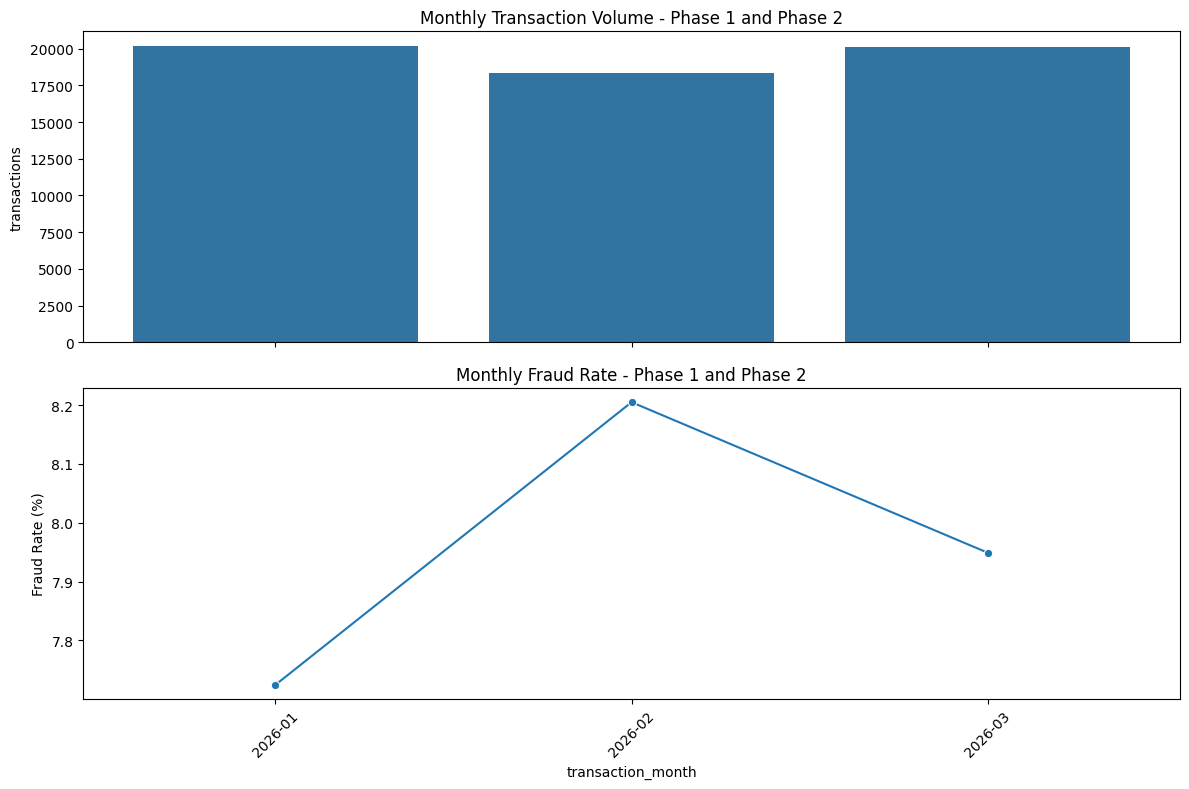

In [80]:
monthly_summary = (
    eda_df.assign(transaction_month=eda_df[TIME_COL].dt.to_period("M").astype(str))
    .groupby("transaction_month")
    .agg(
        transactions=(TARGET_COL, "size"),
        fraud_count=(TARGET_COL, "sum"),
        fraud_rate=(TARGET_COL, "mean")
    )
    .reset_index()
)

monthly_summary["fraud_rate_pct"] = monthly_summary["fraud_rate"] * 100
display(monthly_summary)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.barplot(
    data=monthly_summary,
    x="transaction_month",
    y="transactions",
    ax=axes[0]
)
axes[0].set_title("Monthly Transaction Volume - Phase 1 and Phase 2")

sns.lineplot(
    data=monthly_summary,
    x="transaction_month",
    y="fraud_rate_pct",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Monthly Fraud Rate - Phase 1 and Phase 2")
axes[1].set_ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,drift_phase,transactions,start_date,end_date
0,1,38476,2026-01-01 00:00:00,2026-02-28 23:59:00
1,2,20141,2026-03-01 00:02:00,2026-03-31 23:58:00
2,3,39945,2026-04-01 00:04:00,2026-05-31 23:57:00
3,4,19545,2026-06-01 00:05:00,2026-06-30 23:58:00


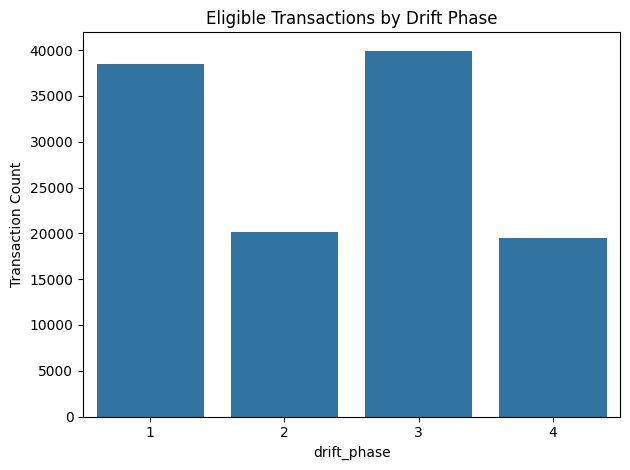

In [81]:
phase_summary = (
    df.groupby(PHASE_COL)
    .agg(
        transactions=(TIME_COL, "size"),
        start_date=(TIME_COL, "min"),
        end_date=(TIME_COL, "max")
    )
    .reset_index()
)

display(phase_summary)

sns.barplot(data=phase_summary, x=PHASE_COL, y="transactions")
plt.title("Eligible Transactions by Drift Phase")
plt.ylabel("Transaction Count")
plt.tight_layout()
plt.show()


In [82]:
feature_audit = pd.DataFrame({
    "feature": candidate_features,
    "dtype": [
        str(train_eda_df[column].dtype)
        for column in candidate_features
    ],
    "missing_percentage": [
        train_eda_df[column].isna().mean() * 100
        for column in candidate_features
    ],
    "unique_values": [
        train_eda_df[column].nunique(dropna=True)
        for column in candidate_features
    ]
})

display(feature_audit)


,feature,dtype,missing_percentage,unique_values
0,transaction_amount,float64,0.0,10859
1,merchant_category,object,0.0,10
2,merchant_country,object,0.0,12
3,transaction_hour,int64,0.0,24
4,transaction_day_of_week,object,0.0,7
5,card_present,int64,0.0,2
6,customer_age,int64,0.0,73
7,customer_country,object,0.0,12
8,account_age_days,int64,0.0,3683
9,credit_limit,float64,0.0,21460


In [83]:
phase_frames = {
    1: df.loc[df[PHASE_COL].eq(1)].copy(),
    2: df.loc[df[PHASE_COL].eq(2)].copy(),
    3: df.loc[df[PHASE_COL].eq(3)].copy(),
    4: df.loc[df[PHASE_COL].eq(4)].copy()
}

train_df = phase_frames[1]
valid_df = phase_frames[2]
test_phase3_df = phase_frames[3]
test_phase4_df = phase_frames[4]

X_train = train_df[candidate_features].copy()
y_train = train_df[TARGET_COL].copy()

X_valid = valid_df[candidate_features].copy()
y_valid = valid_df[TARGET_COL].copy()

X_test_phase3 = test_phase3_df[candidate_features].copy()
y_test_phase3 = test_phase3_df[TARGET_COL].copy()

X_test_phase4 = test_phase4_df[candidate_features].copy()
y_test_phase4 = test_phase4_df[TARGET_COL].copy()

temporal_split_summary = pd.DataFrame({
    "dataset": [
        "Phase 1 - Training",
        "Phase 2 - Validation",
        "Phase 3 - Primary Test",
        "Phase 4 - Secondary Test"
    ],
    "rows": [
        len(X_train),
        len(X_valid),
        len(X_test_phase3),
        len(X_test_phase4)
    ],
    "fraud_count": [
        int(y_train.sum()),
        int(y_valid.sum()),
        int(y_test_phase3.sum()),
        int(y_test_phase4.sum())
    ],
    "fraud_rate_pct": [
        y_train.mean() * 100,
        y_valid.mean() * 100,
        y_test_phase3.mean() * 100,
        y_test_phase4.mean() * 100
    ],
    "start_date": [
        train_df[TIME_COL].min(),
        valid_df[TIME_COL].min(),
        test_phase3_df[TIME_COL].min(),
        test_phase4_df[TIME_COL].min()
    ],
    "end_date": [
        train_df[TIME_COL].max(),
        valid_df[TIME_COL].max(),
        test_phase3_df[TIME_COL].max(),
        test_phase4_df[TIME_COL].max()
    ]
})

display(temporal_split_summary)


,dataset,rows,fraud_count,fraud_rate_pct,start_date,end_date
0,Phase 1 - Training,38476,3060,7.953010,2026-01-01 00:00:00,2026-02-28 23:59:00
1,Phase 2 - Validation,20141,1601,7.948960,2026-03-01 00:02:00,2026-03-31 23:58:00
2,Phase 3 - Primary Test,39945,3208,8.031043,2026-04-01 00:04:00,2026-05-31 23:57:00
3,Phase 4 - Secondary Test,19545,1625,8.314147,2026-06-01 00:05:00,2026-06-30 23:58:00


In [84]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_scaled_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_tree_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_onehot_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("numeric", numeric_scaled_pipeline, numeric_features),
        ("categorical", categorical_onehot_pipeline, categorical_features)
    ],
    remainder="drop"
)

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("numeric", numeric_tree_pipeline, numeric_features),
        ("categorical", categorical_onehot_pipeline, categorical_features)
    ],
    remainder="drop"
)

X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_valid_scaled = preprocessor_scaled.transform(X_valid)
X_test_phase3_scaled = preprocessor_scaled.transform(X_test_phase3)
X_test_phase4_scaled = preprocessor_scaled.transform(X_test_phase4)

X_train_tree = preprocessor_tree.fit_transform(X_train)
X_valid_tree = preprocessor_tree.transform(X_valid)
X_test_phase3_tree = preprocessor_tree.transform(X_test_phase3)
X_test_phase4_tree = preprocessor_tree.transform(X_test_phase4)

print("Scaled feature matrix:", X_train_scaled.shape)
print("Tree feature matrix:", X_train_tree.shape)


Scaled feature matrix: (38476, 79)
Tree feature matrix: (38476, 79)


In [85]:
tabnet_numeric_imputer = SimpleImputer(strategy="median")
tabnet_numeric_scaler = StandardScaler()

X_train_numeric = tabnet_numeric_imputer.fit_transform(
    X_train[numeric_features]
)
X_train_numeric = tabnet_numeric_scaler.fit_transform(
    X_train_numeric
)

X_valid_numeric = tabnet_numeric_scaler.transform(
    tabnet_numeric_imputer.transform(X_valid[numeric_features])
)
X_test_phase3_numeric = tabnet_numeric_scaler.transform(
    tabnet_numeric_imputer.transform(X_test_phase3[numeric_features])
)
X_test_phase4_numeric = tabnet_numeric_scaler.transform(
    tabnet_numeric_imputer.transform(X_test_phase4[numeric_features])
)

tabnet_categorical_imputer = SimpleImputer(strategy="most_frequent")
X_train_categorical_imputed = tabnet_categorical_imputer.fit_transform(
    X_train[categorical_features]
)
X_valid_categorical_imputed = tabnet_categorical_imputer.transform(
    X_valid[categorical_features]
)
X_test_phase3_categorical_imputed = tabnet_categorical_imputer.transform(
    X_test_phase3[categorical_features]
)
X_test_phase4_categorical_imputed = tabnet_categorical_imputer.transform(
    X_test_phase4[categorical_features]
)

tabnet_categorical_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    dtype=np.float32
)

X_train_categorical = tabnet_categorical_encoder.fit_transform(
    X_train_categorical_imputed
)
X_valid_categorical = tabnet_categorical_encoder.transform(
    X_valid_categorical_imputed
)
X_test_phase3_categorical = tabnet_categorical_encoder.transform(
    X_test_phase3_categorical_imputed
)
X_test_phase4_categorical = tabnet_categorical_encoder.transform(
    X_test_phase4_categorical_imputed
)

X_train_categorical = np.where(
    X_train_categorical < 0, 0, X_train_categorical + 1
).astype(np.float32)
X_valid_categorical = np.where(
    X_valid_categorical < 0, 0, X_valid_categorical + 1
).astype(np.float32)
X_test_phase3_categorical = np.where(
    X_test_phase3_categorical < 0, 0, X_test_phase3_categorical + 1
).astype(np.float32)
X_test_phase4_categorical = np.where(
    X_test_phase4_categorical < 0, 0, X_test_phase4_categorical + 1
).astype(np.float32)

X_train_tabnet = np.concatenate(
    [X_train_numeric, X_train_categorical], axis=1
).astype(np.float32)
X_valid_tabnet = np.concatenate(
    [X_valid_numeric, X_valid_categorical], axis=1
).astype(np.float32)
X_test_phase3_tabnet = np.concatenate(
    [X_test_phase3_numeric, X_test_phase3_categorical], axis=1
).astype(np.float32)
X_test_phase4_tabnet = np.concatenate(
    [X_test_phase4_numeric, X_test_phase4_categorical], axis=1
).astype(np.float32)

cat_idxs = list(
    range(len(numeric_features), len(numeric_features) + len(categorical_features))
)
cat_dims = [
    len(categories) + 1
    for categories in tabnet_categorical_encoder.categories_
]
cat_emb_dim = [
    min(8, max(2, int(np.ceil(np.sqrt(dimension))))
    )
    for dimension in cat_dims
]

print("TabNet train matrix:", X_train_tabnet.shape)
print("Categorical feature indexes:", cat_idxs)
print("Categorical dimensions:", cat_dims)


TabNet train matrix: (38476, 23)
Categorical feature indexes: [15, 16, 17, 18, 19, 20, 21, 22]
Categorical dimensions: [11, 13, 8, 13, 6, 6, 7, 8]


In [86]:
class AveragePrecisionMetric(Metric):
    def __init__(self):
        self._name = "average_precision"
        self._maximize = True

    def __call__(self, y_true, y_score):
        return average_precision_score(y_true, y_score[:, 1])


class_ratio = (len(y_train) - y_train.sum()) / y_train.sum()

def calculate_metrics(y_true, probabilities):
    predictions = (probabilities >= PREDICTION_THRESHOLD).astype(int)
    return {
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "MCC": matthews_corrcoef(y_true, predictions)
    }


In [87]:
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=class_ratio,
        eval_metric="logloss",
        n_jobs=-1,
        random_state=SEED
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        class_weight="balanced",
        verbosity=-1,
        n_jobs=-1,
        random_state=SEED
    )
}

baseline_models["Logistic Regression"].fit(X_train_scaled, y_train)
baseline_models["Random Forest"].fit(X_train_tree, y_train)
baseline_models["XGBoost"].fit(X_train_tree, y_train)
baseline_models["LightGBM"].fit(X_train_tree, y_train)


LGBMClassifier(class_weight='balanced', learning_rate=0.05, n_estimators=300,
               n_jobs=-1, random_state=42, verbosity=-1)

In [88]:
tabnet_baseline = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=5,
    gamma=1.5,
    lambda_sparse=1e-4,
    cat_idxs=cat_idxs,
    cat_dims=cat_dims,
    cat_emb_dim=cat_emb_dim,
    optimizer_fn=torch.optim.Adam,
    optimizer_params={"lr": 2e-2},
    mask_type="sparsemax",
    seed=SEED,
    verbose=0
)

tabnet_baseline.fit(
    X_train_tabnet,
    y_train.to_numpy(),
    eval_set=[(X_valid_tabnet, y_valid.to_numpy())],
    eval_name=["validation"],
    eval_metric=[AveragePrecisionMetric],
    max_epochs=TABNET_MAX_EPOCHS,
    patience=TABNET_PATIENCE,
    batch_size=512,
    virtual_batch_size=128,
    weights=1
)



Early stopping occurred at epoch 17 with best_epoch = 14 and best_validation_average_precision = 0.74886


In [89]:

def tabnet_objective(trial):

    params = {
        "n_d": trial.suggest_categorical("n_d", [8, 16, 24, 32]),
        "n_a": trial.suggest_categorical("n_a", [8, 16, 24, 32]),
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.0, 1.8),
        "lambda_sparse": trial.suggest_float(
            "lambda_sparse", 1e-5, 1e-3, log=True
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-3, 2e-2, log=True
        )
    }

    model = TabNetClassifier(
        n_d=params["n_d"],
        n_a=params["n_a"],
        n_steps=params["n_steps"],
        gamma=params["gamma"],
        lambda_sparse=params["lambda_sparse"],
        cat_idxs=cat_idxs,
        cat_dims=cat_dims,
        cat_emb_dim=cat_emb_dim,
        optimizer_fn=torch.optim.Adam,
        optimizer_params={"lr": params["learning_rate"]},
        mask_type="sparsemax",
        seed=SEED,
        verbose=0
    )

    model.fit(
        X_train_tabnet,
        y_train.to_numpy(),
        eval_set=[
            (X_valid_tabnet, y_valid.to_numpy())
        ],
        eval_name=["validation"],
        eval_metric=[AveragePrecisionMetric],
        max_epochs=TABNET_MAX_EPOCHS,
        patience=TABNET_PATIENCE,
        batch_size=512,
        virtual_batch_size=128,
        weights=1
    )

    probabilities = model.predict_proba(
        X_valid_tabnet
    )[:, 1]

    return average_precision_score(
        y_valid,
        probabilities
    )


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED)
)

study.enqueue_trial({
    "n_d": 16,
    "n_a": 16,
    "n_steps": 5,
    "gamma": 1.5,
    "lambda_sparse": 1e-4,
    "learning_rate": 0.02
})

study.optimize(
    tabnet_objective,
    n_trials=30
)

best_tabnet_params = study.best_params
best_validation_pr_auc = study.best_value

print("Best Validation PR-AUC:", best_validation_pr_auc)
print("Best Parameters:", best_tabnet_params)

display(study.trials_dataframe().sort_values("value", ascending=False).head(10))


[I 2026-11-10 10:05:26,843] A new study created in memory with name: no-name-2f1b98b1-976e-4c33-9c60-d2e32d30a337



Early stopping occurred at epoch 17 with best_epoch = 14 and best_validation_average_precision = 0.74886


[I 2026-11-10 10:06:39,680] Trial 0 finished with value: 0.7488612685978266 and parameters: {'n_d': 16, 'n_a': 16, 'n_steps': 5, 'gamma': 1.5, 'lambda_sparse': 0.0001, 'learning_rate': 0.02}. Best is trial 0 with value: 0.7488612685978266.



Early stopping occurred at epoch 11 with best_epoch = 8 and best_validation_average_precision = 0.67036


[I 2026-11-10 10:07:28,977] Trial 1 finished with value: 0.6703649138244914 and parameters: {'n_d': 16, 'n_a': 32, 'n_steps': 5, 'gamma': 1.5664580622368365, 'lambda_sparse': 1.0994335574766187e-05, 'learning_rate': 0.018276027831785738}. Best is trial 0 with value: 0.7488612685978266.



Early stopping occurred at epoch 26 with best_epoch = 23 and best_validation_average_precision = 0.74657


... (53 outputs left out)


Early stopping occurred at epoch 17 with best_epoch = 14 and best_validation_average_precision = 0.75777


[I 2026-11-10 10:44:14,842] Trial 29 finished with value: 0.7577706307082606 and parameters: {'n_d': 8, 'n_a': 16, 'n_steps': 4, 'gamma': 1.3030971917421859, 'lambda_sparse': 6.656707371781762e-05, 'learning_rate': 0.007725685629283045}. Best is trial 28 with value: 0.7826110951392337.


Best Validation PR-AUC: 0.7826110951392337
Best Parameters: {'n_d': 8, 'n_a': 16, 'n_steps': 4, 'gamma': 1.0602769975841746, 'lambda_sparse': 0.00010160081749801643, 'learning_rate': 0.007876946762003014}


,number,value,datetime_start,datetime_complete,duration,params_gamma,params_lambda_sparse,params_learning_rate,params_n_a,params_n_d,params_n_steps,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
28,28,0.782611,2026-11-10 10:41:35.792922,2026-11-10 10:43:14.533597,0 days 00:01:38.740675,1.060277,0.000102,0.007877,16,8,4,NaN,"{""gamma"": 1.0602769975841746, ""lambda_sparse"":...",COMPLETE
19,19,0.777673,2026-11-10 10:28:59.616870,2026-11-10 10:30:56.416869,0 days 00:01:56.799999,1.273694,0.000147,0.010017,16,8,6,NaN,"{""gamma"": 1.2736942076190267, ""lambda_sparse"":...",COMPLETE
26,26,0.776891,2026-11-10 10:39:30.809721,2026-11-10 10:40:49.279700,0 days 00:01:18.469979,1.012170,0.000077,0.012203,16,8,5,NaN,"{""gamma"": 1.0121703952564174, ""lambda_sparse"":...",COMPLETE
9,9,0.776589,2026-11-10 10:16:39.988611,2026-11-10 10:18:41.233511,0 days 00:02:01.244900,1.199434,0.000066,0.009616,16,8,6,NaN,NaN,COMPLETE
27,27,0.775106,2026-11-10 10:40:49.280796,2026-11-10 10:41:35.792021,0 days 00:00:46.511225,1.041431,0.000171,0.015366,16,8,3,NaN,"{""gamma"": 1.041431402687435, ""lambda_sparse"": ...",COMPLETE
24,24,0.773592,2026-11-10 10:37:00.684047,2026-11-10 10:38:35.338234,0 days 00:01:34.654187,1.198338,0.000041,0.012695,16,32,6,NaN,"{""gamma"": 1.1983378442153596, ""lambda_sparse"":...",COMPLETE
23,23,0.773322,2026-11-10 10:34:33.226941,2026-11-10 10:37:00.683048,0 days 00:02:27.456107,1.289044,0.000079,0.017178,16,32,6,NaN,"{""gamma"": 1.2890444825295846, ""lambda_sparse"":...",COMPLETE
25,25,0.768746,2026-11-10 10:38:35.339501,2026-11-10 10:39:30.808702,0 days 00:00:55.469201,1.000223,0.000143,0.007618,16,8,6,NaN,"{""gamma"": 1.0002227700111694, ""lambda_sparse"":...",COMPLETE
13,13,0.762068,2026-11-10 10:21:50.925598,2026-11-10 10:23:05.489518,0 days 00:01:14.563920,1.179698,0.000019,0.009115,16,8,5,NaN,"{""gamma"": 1.1796977690595294, ""lambda_sparse"":...",COMPLETE
29,29,0.757771,2026-11-10 10:43:14.534616,2026-11-10 10:44:14.841939,0 days 00:01:00.307323,1.303097,0.000067,0.007726,16,8,4,NaN,"{""gamma"": 1.3030971917421859, ""lambda_sparse"":...",COMPLETE


In [90]:
optimized_tabnet = TabNetClassifier(
    n_d=best_tabnet_params["n_d"],
    n_a=best_tabnet_params["n_a"],
    n_steps=best_tabnet_params["n_steps"],
    gamma=best_tabnet_params["gamma"],
    lambda_sparse=best_tabnet_params["lambda_sparse"],
    cat_idxs=cat_idxs,
    cat_dims=cat_dims,
    cat_emb_dim=cat_emb_dim,
    optimizer_fn=torch.optim.Adam,
    optimizer_params={
        "lr": best_tabnet_params["learning_rate"]
    },
    mask_type="sparsemax",
    seed=SEED,
    verbose=0
)

optimized_tabnet.fit(
    X_train_tabnet,
    y_train.to_numpy(),
    eval_set=[
        (X_valid_tabnet, y_valid.to_numpy())
    ],
    eval_name=["validation"],
    eval_metric=[AveragePrecisionMetric],
    max_epochs=TABNET_MAX_EPOCHS,
    patience=TABNET_PATIENCE,
    batch_size=512,
    virtual_batch_size=128,
    weights=1
)



Early stopping occurred at epoch 29 with best_epoch = 26 and best_validation_average_precision = 0.78261


In [91]:
evaluation_sets = {
    "Phase 2 - Validation": {
        "y": y_valid,
        "X_scaled": X_valid_scaled,
        "X_tree": X_valid_tree,
        "X_tabnet": X_valid_tabnet
    },
    "Phase 3 - Primary Test": {
        "y": y_test_phase3,
        "X_scaled": X_test_phase3_scaled,
        "X_tree": X_test_phase3_tree,
        "X_tabnet": X_test_phase3_tabnet
    },
    "Phase 4 - Secondary Test": {
        "y": y_test_phase4,
        "X_scaled": X_test_phase4_scaled,
        "X_tree": X_test_phase4_tree,
        "X_tabnet": X_test_phase4_tabnet
    }
}

model_probabilities = {}
metric_rows = []

for phase_name, phase_data in evaluation_sets.items():
    phase_models = {
        "Logistic Regression": (
            baseline_models["Logistic Regression"],
            phase_data["X_scaled"]
        ),
        "Random Forest": (
            baseline_models["Random Forest"],
            phase_data["X_tree"]
        ),
        "XGBoost": (
            baseline_models["XGBoost"],
            phase_data["X_tree"]
        ),
        "LightGBM": (
            baseline_models["LightGBM"],
            phase_data["X_tree"]
        ),
        "TabNet Baseline": (
            tabnet_baseline,
            phase_data["X_tabnet"]
        ),
        "Optimized TabNet": (
            optimized_tabnet,
            phase_data["X_tabnet"]
        )
    }

    for model_name, (model, X_eval) in phase_models.items():
        probabilities = model.predict_proba(X_eval)[:, 1]
        model_probabilities[(model_name, phase_name)] = probabilities
        metric_rows.append({
            "Model": model_name,
            "Phase": phase_name,
            **calculate_metrics(phase_data["y"], probabilities)
        })

evaluation_results = pd.DataFrame(metric_rows)

display(
    evaluation_results
    .sort_values(["Phase", "PR-AUC"], ascending=[True, False])
    .round(4)
)


,Model,Phase,PR-AUC,Precision,Recall,F1-Score,ROC-AUC,MCC
2,XGBoost,Phase 2 - Validation,0.8199,0.5047,0.8782,0.6410,0.9652,0.6298
3,LightGBM,Phase 2 - Validation,0.8191,0.5258,0.8720,0.6560,0.9657,0.6429
5,Optimized TabNet,Phase 2 - Validation,0.7826,0.4334,0.8801,0.5808,0.9584,0.5740
1,Random Forest,Phase 2 - Validation,0.7666,0.8297,0.5415,0.6553,0.9548,0.6488
4,TabNet Baseline,Phase 2 - Validation,0.7489,0.3936,0.8751,0.5430,0.9468,0.5381
0,Logistic Regression,Phase 2 - Validation,0.4780,0.3279,0.8101,0.4668,0.9064,0.4539
9,LightGBM,Phase 3 - Primary Test,0.8060,0.5081,0.8579,0.6382,0.9597,0.6234
8,XGBoost,Phase 3 - Primary Test,0.8055,0.4879,0.8622,0.6232,0.9583,0.6099
11,Optimized TabNet,Phase 3 - Primary Test,0.7634,0.4152,0.8619,0.5604,0.9517,0.5511
7,Random Forest,Phase 3 - Primary Test,0.7436,0.8035,0.5087,0.6230,0.9504,0.6159


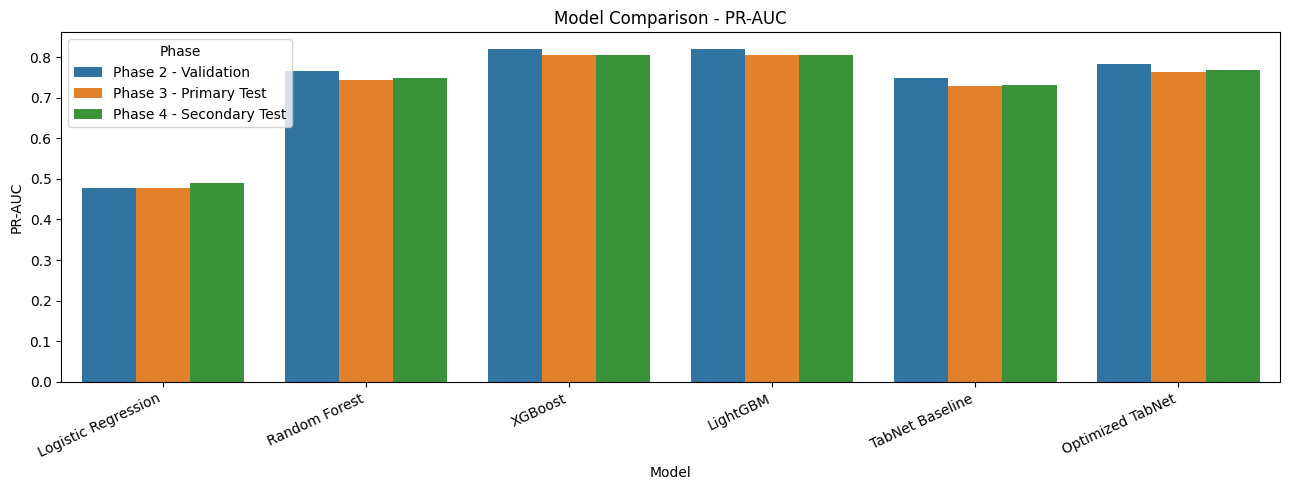

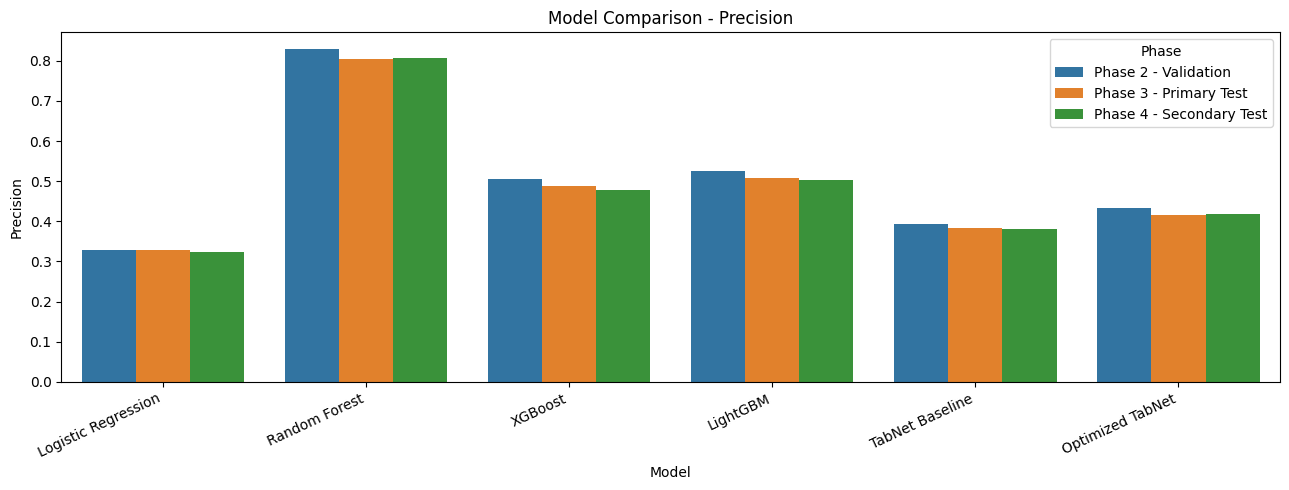

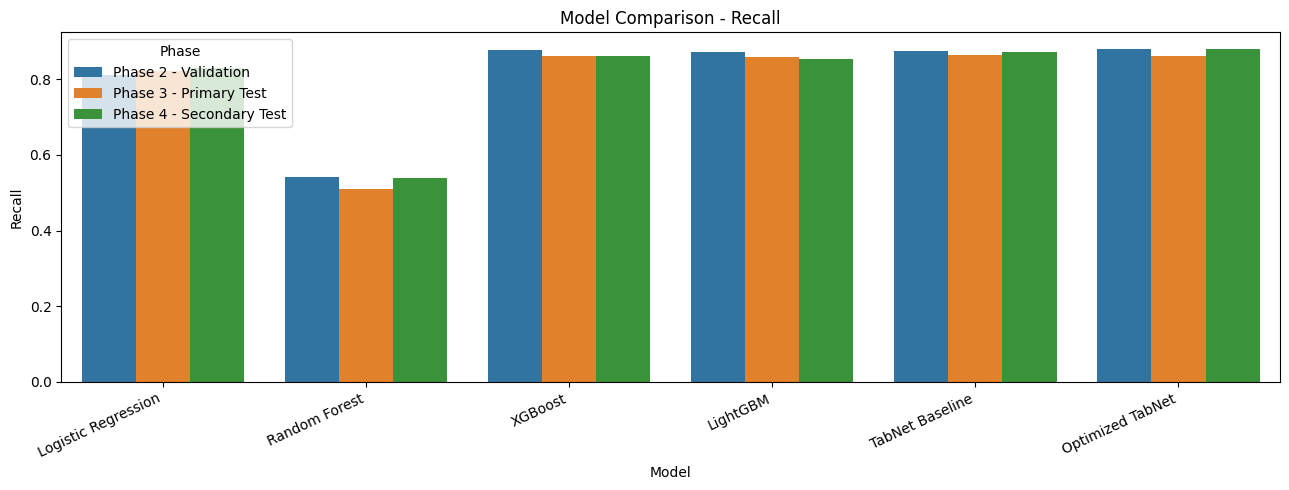

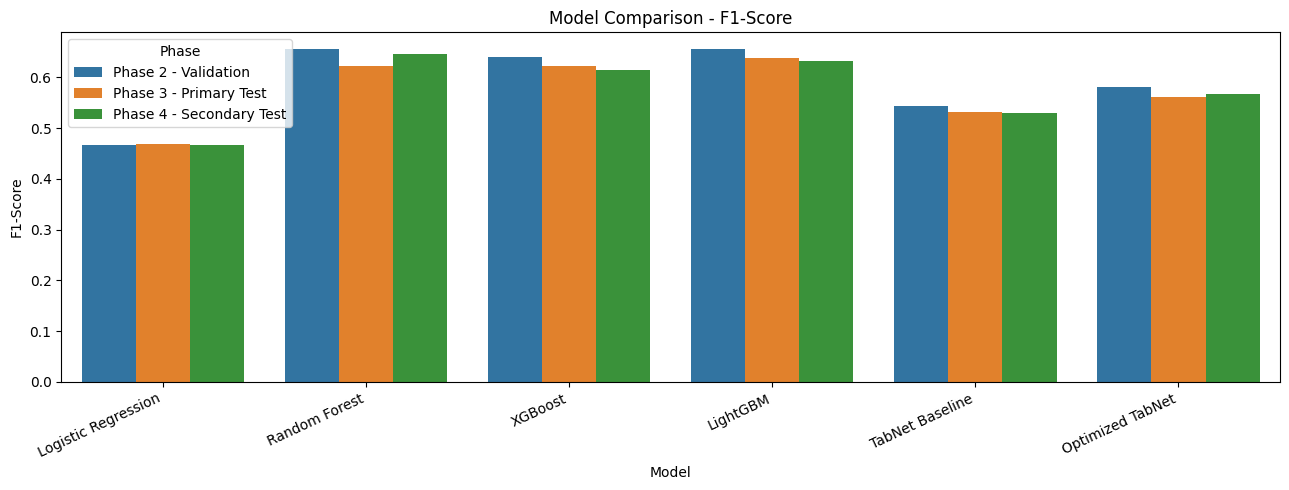

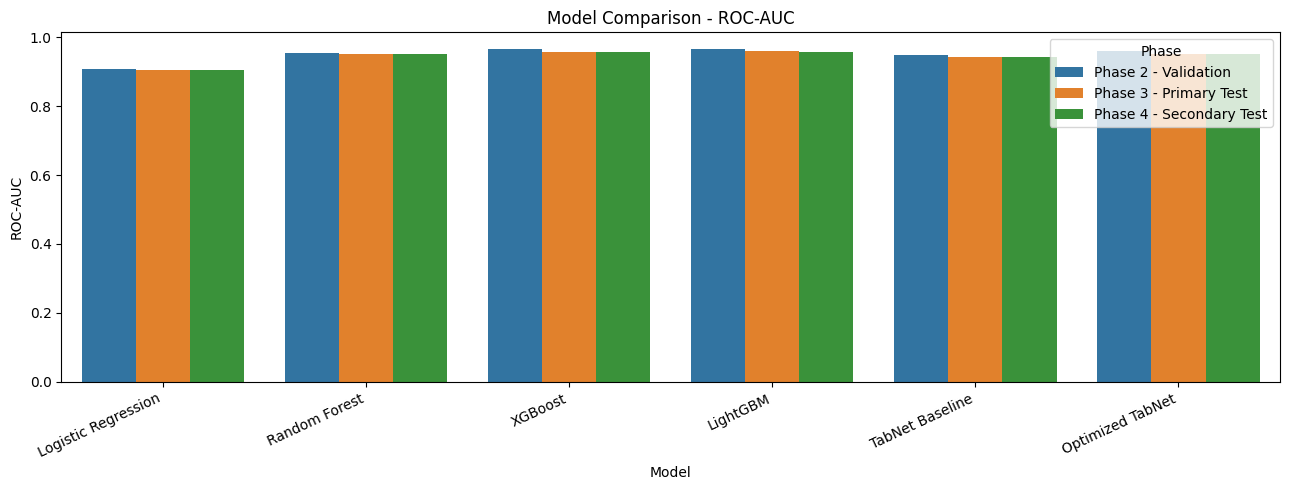

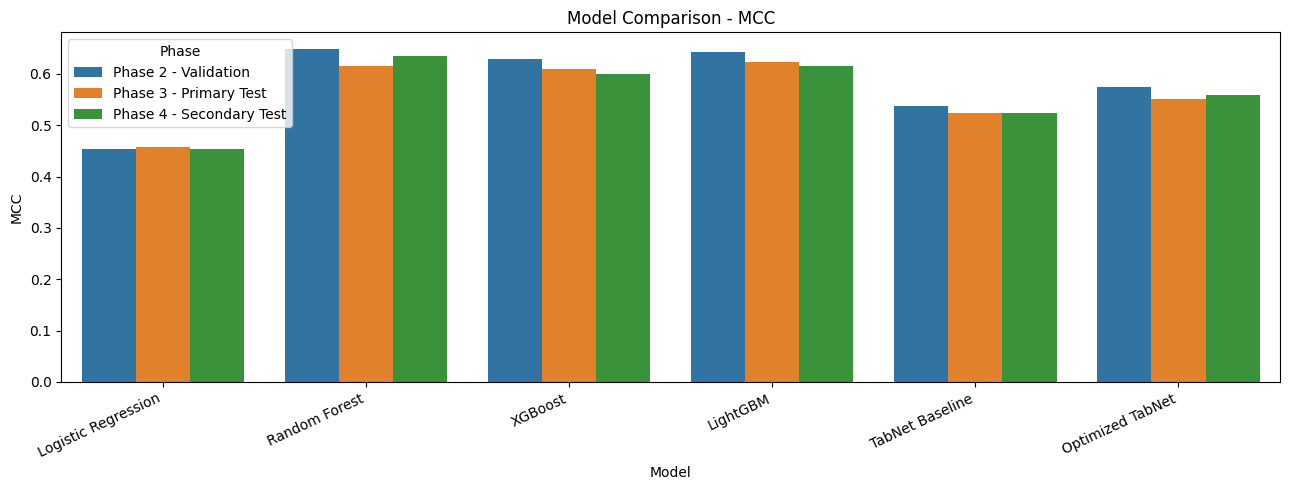

In [92]:
for metric in [
    "PR-AUC",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "MCC"
]:
    plt.figure(figsize=(13, 5))
    sns.barplot(
        data=evaluation_results,
        x="Model",
        y=metric,
        hue="Phase"
    )
    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


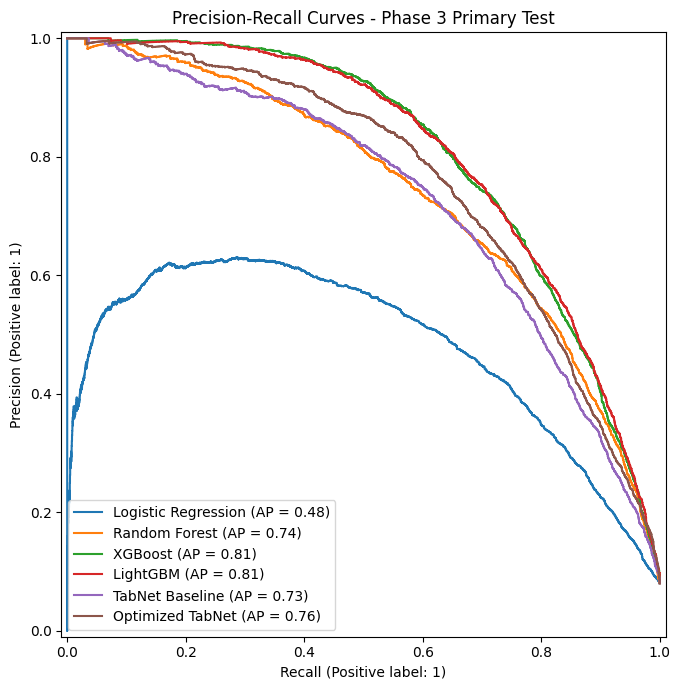

In [93]:
phase3_probabilities = {
    model_name: model_probabilities[
        (model_name, "Phase 3 - Primary Test")
    ]
    for model_name in [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "TabNet Baseline",
        "Optimized TabNet"
    ]
}

plt.figure(figsize=(9, 7))
for model_name, probabilities in phase3_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test_phase3,
        probabilities,
        name=model_name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curves - Phase 3 Primary Test")
plt.tight_layout()
plt.show()


,Model,Phase,PR-AUC,Precision,Recall,F1-Score,ROC-AUC,MCC
9,LightGBM,Phase 3 - Primary Test,0.8060,0.5081,0.8579,0.6382,0.9597,0.6234
8,XGBoost,Phase 3 - Primary Test,0.8055,0.4879,0.8622,0.6232,0.9583,0.6099
11,Optimized TabNet,Phase 3 - Primary Test,0.7634,0.4152,0.8619,0.5604,0.9517,0.5511
7,Random Forest,Phase 3 - Primary Test,0.7436,0.8035,0.5087,0.6230,0.9504,0.6159
10,TabNet Baseline,Phase 3 - Primary Test,0.7298,0.3834,0.8628,0.5309,0.9437,0.5238
6,Logistic Regression,Phase 3 - Primary Test,0.4785,0.3281,0.8214,0.4689,0.9040,0.4574


,Model,Phase,PR-AUC,Precision,Recall,F1-Score,ROC-AUC,MCC
14,XGBoost,Phase 4 - Secondary Test,0.8050,0.4779,0.8603,0.6145,0.9573,0.5999
15,LightGBM,Phase 4 - Secondary Test,0.8043,0.5022,0.8523,0.6320,0.9578,0.6152
17,Optimized TabNet,Phase 4 - Secondary Test,0.7692,0.4194,0.8800,0.5680,0.9513,0.5598
13,Random Forest,Phase 4 - Secondary Test,0.7489,0.8072,0.5385,0.6460,0.9502,0.6355
16,TabNet Baseline,Phase 4 - Secondary Test,0.7308,0.3814,0.8726,0.5308,0.9438,0.5236
12,Logistic Regression,Phase 4 - Secondary Test,0.4895,0.3241,0.8295,0.4661,0.9049,0.4538


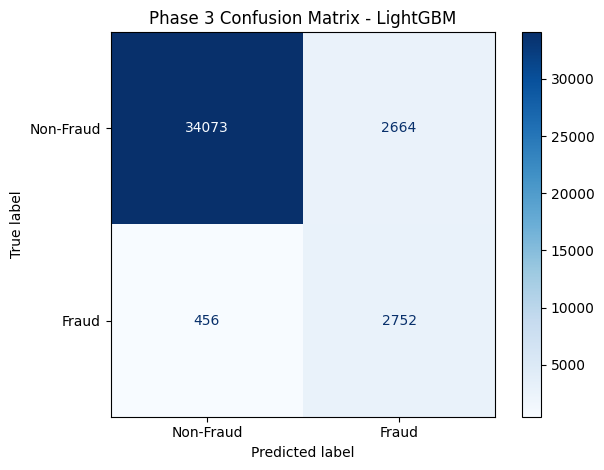

In [94]:
phase3_results = evaluation_results.loc[
    evaluation_results["Phase"].eq("Phase 3 - Primary Test")
].sort_values("PR-AUC", ascending=False)

phase4_results = evaluation_results.loc[
    evaluation_results["Phase"].eq("Phase 4 - Secondary Test")
].sort_values("PR-AUC", ascending=False)

display(phase3_results.round(4))
display(phase4_results.round(4))

best_phase3_model_name = phase3_results.iloc[0]["Model"]
best_phase3_probabilities = model_probabilities[
    (best_phase3_model_name, "Phase 3 - Primary Test")
]
best_phase3_predictions = (
    best_phase3_probabilities >= PREDICTION_THRESHOLD
).astype(int)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test_phase3,
        best_phase3_predictions
    ),
    display_labels=["Non-Fraud", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title(f"Phase 3 Confusion Matrix - {best_phase3_model_name}")
plt.tight_layout()
plt.show()


In [95]:
optuna_trials = study.trials_dataframe()

display(
    optuna_trials
    .sort_values("value", ascending=False)
    .head(10)
)


,number,value,datetime_start,datetime_complete,duration,params_gamma,params_lambda_sparse,params_learning_rate,params_n_a,params_n_d,params_n_steps,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
28,28,0.782611,2026-11-10 10:41:35.792922,2026-11-10 10:43:14.533597,0 days 00:01:38.740675,1.060277,0.000102,0.007877,16,8,4,NaN,"{""gamma"": 1.0602769975841746, ""lambda_sparse"":...",COMPLETE
19,19,0.777673,2026-11-10 10:28:59.616870,2026-11-10 10:30:56.416869,0 days 00:01:56.799999,1.273694,0.000147,0.010017,16,8,6,NaN,"{""gamma"": 1.2736942076190267, ""lambda_sparse"":...",COMPLETE
26,26,0.776891,2026-11-10 10:39:30.809721,2026-11-10 10:40:49.279700,0 days 00:01:18.469979,1.012170,0.000077,0.012203,16,8,5,NaN,"{""gamma"": 1.0121703952564174, ""lambda_sparse"":...",COMPLETE
9,9,0.776589,2026-11-10 10:16:39.988611,2026-11-10 10:18:41.233511,0 days 00:02:01.244900,1.199434,0.000066,0.009616,16,8,6,NaN,NaN,COMPLETE
27,27,0.775106,2026-11-10 10:40:49.280796,2026-11-10 10:41:35.792021,0 days 00:00:46.511225,1.041431,0.000171,0.015366,16,8,3,NaN,"{""gamma"": 1.041431402687435, ""lambda_sparse"": ...",COMPLETE
24,24,0.773592,2026-11-10 10:37:00.684047,2026-11-10 10:38:35.338234,0 days 00:01:34.654187,1.198338,0.000041,0.012695,16,32,6,NaN,"{""gamma"": 1.1983378442153596, ""lambda_sparse"":...",COMPLETE
23,23,0.773322,2026-11-10 10:34:33.226941,2026-11-10 10:37:00.683048,0 days 00:02:27.456107,1.289044,0.000079,0.017178,16,32,6,NaN,"{""gamma"": 1.2890444825295846, ""lambda_sparse"":...",COMPLETE
25,25,0.768746,2026-11-10 10:38:35.339501,2026-11-10 10:39:30.808702,0 days 00:00:55.469201,1.000223,0.000143,0.007618,16,8,6,NaN,"{""gamma"": 1.0002227700111694, ""lambda_sparse"":...",COMPLETE
13,13,0.762068,2026-11-10 10:21:50.925598,2026-11-10 10:23:05.489518,0 days 00:01:14.563920,1.179698,0.000019,0.009115,16,8,5,NaN,"{""gamma"": 1.1796977690595294, ""lambda_sparse"":...",COMPLETE
29,29,0.757771,2026-11-10 10:43:14.534616,2026-11-10 10:44:14.841939,0 days 00:01:00.307323,1.303097,0.000067,0.007726,16,8,4,NaN,"{""gamma"": 1.3030971917421859, ""lambda_sparse"":...",COMPLETE


In [96]:
evaluation_results.to_csv(
    OUTPUT_DIR / "model_evaluation_results.csv",
    index=False
)

temporal_split_summary.to_csv(
    OUTPUT_DIR / "temporal_split_summary.csv",
    index=False
)

feature_audit.to_csv(
    OUTPUT_DIR / "selected_feature_audit.csv",
    index=False
)

optuna_trials.to_csv(
    OUTPUT_DIR / "tabnet_optuna_trials.csv",
    index=False
)

with open(
    OUTPUT_DIR / "best_tabnet_params.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(best_tabnet_params, file, indent=4)

for phase_name, phase_data in evaluation_sets.items():
    prediction_frame = pd.DataFrame(
        {"actual_is_fraud": phase_data["y"].to_numpy()},
        index=phase_data["y"].index
    )

    for model_name in [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "TabNet Baseline",
        "Optimized TabNet"
    ]:
        prediction_frame[f"{model_name}_probability"] = model_probabilities[
            (model_name, phase_name)
        ]

    output_name = (
        phase_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_frame.to_csv(
        OUTPUT_DIR / f"predictions_{output_name}.csv",
        index=True
    )

joblib.dump(
    preprocessor_scaled,
    OUTPUT_DIR / "preprocessor_scaled.joblib"
)

joblib.dump(
    preprocessor_tree,
    OUTPUT_DIR / "preprocessor_tree.joblib"
)

joblib.dump(
    baseline_models,
    OUTPUT_DIR / "baseline_models.joblib"
)

joblib.dump(
    {
        "numeric_imputer": tabnet_numeric_imputer,
        "numeric_scaler": tabnet_numeric_scaler,
        "categorical_imputer": tabnet_categorical_imputer,
        "categorical_encoder": tabnet_categorical_encoder,
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "feature_columns": candidate_features,
        "categorical_indexes": cat_idxs,
        "categorical_dimensions": cat_dims
    },
    OUTPUT_DIR / "tabnet_preprocessing.joblib"
)

tabnet_baseline.save_model(str(OUTPUT_DIR / "tabnet_baseline"))
optimized_tabnet.save_model(str(OUTPUT_DIR / "optimized_tabnet"))

print("All experiment outputs saved to:", OUTPUT_DIR.resolve())


Successfully saved model at results/tabnet_baseline.zip
Successfully saved model at results/optimized_tabnet.zip
All experiment outputs saved to: /kaggle/working/results
